# XGBoost — Explainable Credit Risk

This notebook trains the **XGBoost** model for the project *Explainable Credit Risk: SHAP, LIME, and Counterfactual Explanations for Black-Box Credit Models*.

XGBoost is the project's **black-box model**: it should predict default better than logistic regression, but it's much harder to read directly. That's what the SHAP / LIME / counterfactual part then opens up.

**To keep the comparison fair, this notebook uses exactly the same setup as `02_neural_network.ipynb`:**

| Item | Setting (identical across models) |
| --- | --- |
| Data | `../data/default of credit card clients.xls`, `header=1` |
| Target | `DEFAULT` (renamed from `default payment next month`) |
| Features `X` | all columns except `ID` and `DEFAULT` (23 predictors) |
| Split | `train_test_split(test_size=0.20, stratify=y, random_state=42)` |
| Preprocessing | same `ColumnTransformer`: `StandardScaler` on numeric, `OneHotEncoder` on `SEX`, `EDUCATION`, `MARRIAGE` |
| Metrics | same `evaluate_classifier()` function: Accuracy, ROC-AUC, Precision, Recall, F1 + confusion matrix |
| Decision threshold | 0.50 (default `.predict()`) |

**Notebook outline**
1. Load and inspect the data
2. Define X / y and split into train / test
3. Preprocess
4. Train XGBoost (with early stopping)
5. Evaluate on the test set and compare with the neural network
6. Look at XGBoost's built-in feature importance and why it isn't enough
7. Prepare for the explainers: raw-input prediction function and the selected high-risk applicant

**Experimental scope:** Configuration A uses the 30,000-row Excel dataset, 23 predictors and an 80/20 stratified split (seed 42). The separate PyCaret explainability experiment uses different data, predictors and a split; its metrics are not directly comparable. Recorded outputs are retained from the original notebooks. See `../RESULTS.md` for verification status. Run this notebook with `notebooks/` as the working directory.


## 1. Imports and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# XGBoost: gradient-boosted decision trees. Install with: pip install xgboost
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
)

# Same seed as every other notebook in the project -> reproducible results
RANDOM_STATE = 42

# Optional generated figures; this folder is created when the notebook runs
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

In [2]:
# Same path and reading options as 02_neural_network.ipynb.
# header=1 because the first row of the Excel file is a second header line (X1, X2, ...).
# Note: reading a .xls file requires the 'xlrd' package (pip install xlrd).
DATA_PATH = "../data/default of credit card clients.xls"

df = pd.read_excel(DATA_PATH, header=1)

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
df.shape  # 30,000 clients; 23 predictors + ID + target

(30000, 25)

In [4]:
# We simplify the target name: "default payment next month" -> "DEFAULT"
df = df.rename(
    columns={"default payment next month": "DEFAULT"}
)

# Class balance: about 22% of clients default. The data is imbalanced,
# which is why accuracy alone is not a good metric (a model that always says
# "no default" would already get ~78% accuracy).
df["DEFAULT"].value_counts(normalize=True)

DEFAULT
0    0.7788
1    0.2212
Name: proportion, dtype: float64

## 2. X / y definition and train / test split (identical to the other models)

In [5]:
# ID is just a client identifier, not an economic characteristic -> dropped.
X = df.drop(columns=["ID", "DEFAULT"])
y = df["DEFAULT"]

In [6]:
# Train / test split. IMPORTANT: identical to 02_neural_network.ipynb and logistic regression.
# Same test_size, same stratify, same random_state -> the exact same 6,000 test clients.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,  # Keeps approximately the same percentage of defaults in train and test
    random_state=RANDOM_STATE
)

In [7]:
# Should be Train: 24,000 and Test: 6,000, with ~22.1% defaults in both.
print(X_train.shape)
print(X_test.shape)

print(y_train.mean())
print(y_test.mean())

# Extra check: the first test-set index should be the same in every teammate's notebook.
# If this differs from someone else's notebook, the splits are not identical.
print("First 5 test indices:", X_test.index[:5].tolist())

(24000, 23)
(6000, 23)
0.22120833333333334
0.22116666666666668
First 5 test indices: [6907, 24575, 26766, 2156, 3179]


## 3. Preprocessing (identical to the other models)

We reuse exactly the same `ColumnTransformer` as the neural network:
- **numeric features** -> `StandardScaler` (mean 0, std 1)
- **categorical features** (`SEX`, `EDUCATION`, `MARRIAGE`) -> one-hot dummies

**Does XGBoost need scaling?** No. Decision trees split on thresholds ("is `PAY_0` > 1.5?"), and rescaling a variable just moves the threshold; the splits and predictions come out the same. Scaling therefore neither helps nor hurts XGBoost. We keep it anyway so that **all models see exactly the same inputs**, which is what the comparison requires.

One-hot encoding *does* matter: it stops the model from treating `EDUCATION = 4` as "twice" `EDUCATION = 2`.

In [8]:
# ==============================================================================
# 1. FEATURE PARTITIONING (same as 02_neural_network.ipynb)
# ==============================================================================
# Nominal categorical variables: numeric codes that represent categories, not quantities
# (e.g., SEX: 1 = male, 2 = female).
categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
]

# Everything else is numeric: LIMIT_BAL, AGE, PAY_0..PAY_6, BILL_AMT1..6, PAY_AMT1..6
numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]


# ==============================================================================
# 2. PREPROCESSING PIPELINE (same as 02_neural_network.ipynb)
# ==============================================================================
preprocessor = ColumnTransformer(
    transformers=[
        # Scale numeric variables to mean 0, std 1
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        # One-hot encode categorical variables
        # - handle_unknown="ignore": no crash if the test set has an unseen category
        # - sparse_output=False: dense array (needed by SHAP and LIME)
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
    ],
    # Clean names: "SEX_1" instead of "categorical__SEX_1"
    verbose_feature_names_out=False
)


# ==============================================================================
# 3. FIT ON TRAIN ONLY, TRANSFORM BOTH (no data leakage)
# ==============================================================================
X_train_processed = preprocessor.fit_transform(X_train)  # learns means/stds/categories from TRAIN
X_test_processed = preprocessor.transform(X_test)        # applies them to TEST (never fit on test)

feature_names = preprocessor.get_feature_names_out()

print(X_train_processed.shape)  # (24000, 33): 20 numeric + 13 one-hot columns
feature_names

(24000, 33)


array(['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5',
       'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4',
       'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
       'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'SEX_1', 'SEX_2',
       'EDUCATION_0', 'EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3',
       'EDUCATION_4', 'EDUCATION_5', 'EDUCATION_6', 'MARRIAGE_0',
       'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3'], dtype=object)

## 4. The XGBoost model

**Intuition.** XGBoost builds many small decision trees **one after another**. Each new tree tries to fix the mistakes the earlier trees still make. The final prediction adds up all the trees' outputs (in log-odds), then converts that sum into a probability of default.

A single tree is easy to read. A sum of a few hundred trees, each with up to 16 leaves and many interacting splits, isn't, which is why XGBoost counts as a black box here.

---

#### 1. Tree structure
* **`max_depth=4`**: each tree asks at most 4 questions in a row (up to 2⁴ = 16 leaves). Shallow trees still capture interactions (e.g. *high bill **and** recent late payment*) while limiting overfitting.
* **`min_child_weight=5`**: a split is only allowed if each resulting leaf has enough data behind it, so no rule is built on a handful of clients.

#### 2. Boosting / optimization
* **`n_estimators=2000`**: an *upper limit* on the number of trees. Early stopping (below) picks the actual number.
* **`learning_rate=0.03`**: each new tree's contribution is shrunk to 3%. Smaller steps need more trees but generalize better.
* **`objective="binary:logistic"`**: binary classification; the output is a probability of default.

#### 3. Regularization (against overfitting)
* **`subsample=0.8`**: each tree is trained on a random 80% of the training rows.
* **`colsample_bytree=0.8`**: each tree sees a random 80% of the features. This also helps with our groups of correlated features (`BILL_AMT1..6`, `PAY_0..6`).
* **`reg_lambda=1.0`**: L2 penalty on leaf values (same idea as `alpha` in the neural network).

#### 4. Early stopping (same idea as the neural network)
* We hold out **15% of the training set** as a validation set, the same fraction as the NN's `validation_fraction=0.15`.
* **`eval_metric="logloss"`** is checked on that validation set after every tree.
* **`early_stopping_rounds=50`**: training stops if validation log-loss hasn't improved for 50 trees, and the best iteration is kept.
* The **test set is never used** for training or tuning.

#### 5. Execution
* **`tree_method="hist"`**: fast histogram-based split finding.
* **`random_state=RANDOM_STATE`**: fixes the randomness from `subsample` / `colsample_bytree`.

*Class imbalance:* like the neural network, we **don't** reweight classes (`scale_pos_weight`), so the two models stay comparable at the 0.50 threshold. Section 5 shows what happens if the threshold changes.

In [9]:
# Validation split for EARLY STOPPING, carved out of the TRAINING set only.
# 15% matches the neural network's validation_fraction=0.15.
# The test set (X_test_processed) is untouched until final evaluation.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.15,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print("Inner train:", X_tr.shape, " Validation:", X_val.shape)

Inner train: (20400, 33)  Validation: (3600, 33)


In [10]:
xgb_model = XGBClassifier(
    # Tree structure
    max_depth=4,
    min_child_weight=5,

    # Boosting
    n_estimators=2000,          # upper bound; early stopping chooses the real number
    learning_rate=0.03,
    objective="binary:logistic",

    # Regularization
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,

    # Early stopping (monitored on the validation set passed to .fit)
    eval_metric="logloss",
    early_stopping_rounds=50,

    # Execution
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

In [11]:
# TRAINING
# eval_set: XGBoost reports the loss on each set after every tree.
# The LAST set in the list (validation) is the one used for early stopping.
xgb_model.fit(
    X_tr,
    y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    verbose=False
)

# Number of trees actually kept (best_iteration is 0-based)
print("Best iteration (trees kept):", xgb_model.best_iteration + 1)
print("Best validation log-loss:   ", round(xgb_model.best_score, 4))

Best iteration (trees kept): 284
Best validation log-loss:    0.4291


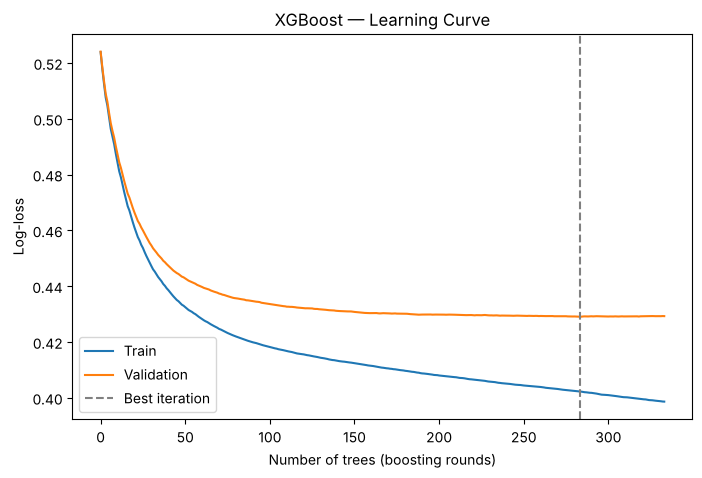

In [12]:
# LEARNING CURVE: train vs validation log-loss as trees are added.
# Train loss keeps falling (the model memorizes more and more of the training data).
# Validation loss flattens out: extra trees stop helping on unseen data (and would eventually hurt).
# Early stopping keeps the number of trees where validation loss was lowest.
evals = xgb_model.evals_result()
train_loss = evals["validation_0"]["logloss"]
val_loss = evals["validation_1"]["logloss"]

plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Train")
plt.plot(val_loss, label="Validation")
plt.axvline(xgb_model.best_iteration, linestyle="--", color="grey", label="Best iteration")
plt.xlabel("Number of trees (boosting rounds)")
plt.ylabel("Log-loss")
plt.title("XGBoost — Learning Curve")
plt.legend()
plt.show()

## 5. Evaluation on the test set (same metrics as the other models)

Note: when early stopping is used, `.predict()` and `.predict_proba()` automatically use only the **best** trees.

In [13]:
# 0 -> non-default, 1 -> default (threshold 0.50, same as the NN)
y_pred_xgb = xgb_model.predict(X_test_processed)

# Estimated probability of DEFAULT for each test client
y_proba_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

In [14]:
# METRICS — exact same function as 02_neural_network.ipynb
def evaluate_classifier(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

xgb_metrics = evaluate_classifier(
    y_test,
    y_pred_xgb,
    y_proba_xgb
)

pd.Series(xgb_metrics)

Accuracy     0.817667
ROC-AUC      0.780463
Precision    0.660248
Recall       0.361718
F1           0.467381
dtype: float64

In [15]:
# Full per-class report (precision / recall / F1 for both classes)
print(classification_report(y_test, y_pred_xgb, target_names=["No Default", "Default"], digits=3))

              precision    recall  f1-score   support

  No Default      0.839     0.947     0.890      4673
     Default      0.660     0.362     0.467      1327

    accuracy                          0.818      6000
   macro avg      0.750     0.654     0.679      6000
weighted avg      0.800     0.818     0.797      6000



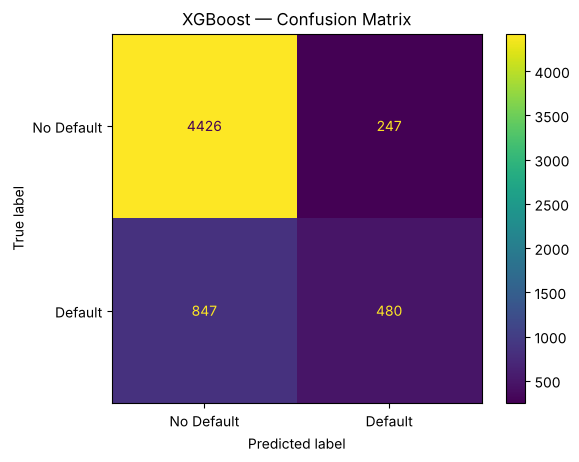

In [16]:
# Confusion Matrix
# Rows = truth, columns = prediction.
# False negatives (bottom-left) are the costly ones for a lender:
# the model said "safe" and the client actually defaulted.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=["No Default", "Default"]
)

plt.title("XGBoost — Confusion Matrix")
plt.savefig(f"{FIG_DIR}/xgb_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

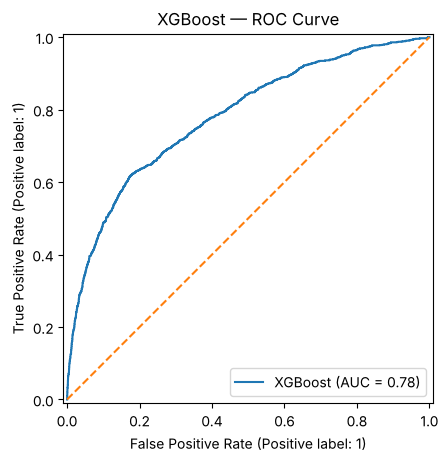

In [17]:
# ROC Curve
# ROC-AUC = probability that a randomly chosen defaulter gets a higher predicted
# default probability than a randomly chosen non-defaulter.
# 0.50 = coin flip, 1.00 = perfect ranking.
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_xgb,
    name="XGBoost"
)

plt.plot([0, 1], [0, 1], linestyle="--")  # random-guess line

plt.title("XGBoost — ROC Curve")
plt.savefig(f"{FIG_DIR}/xgb_roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

### Recorded comparison with Configuration A neural network

The following values are a historical manual transcription of the saved output in `02_neural_network.ipynb`, not live metrics from a shared execution. They match its recorded values. They do not refer to the PyCaret explainability model. See `../RESULTS.md`; do not silently replace these historical results after a rerun.

In [18]:
# Copied from 02_neural_network.ipynb output (test set, threshold 0.50)
nn_metrics_reported = {
    "Accuracy": 0.817833,
    "ROC-AUC": 0.770647,
    "Precision": 0.660714,
    "Recall": 0.362472,
    "F1": 0.468127,
}

comparison = pd.DataFrame({
    "Neural Network": nn_metrics_reported,
    "XGBoost": xgb_metrics,
}).round(4)

comparison

,Neural Network,XGBoost
Accuracy,0.8178,0.8177
ROC-AUC,0.7706,0.7805
Precision,0.6607,0.6602
Recall,0.3625,0.3617
F1,0.4681,0.4674


### Side note: the 0.50 threshold

With 22% defaulters and no class reweighting, both models are **conservative** at 0.50: precision is decent, but recall is low (many defaulters are missed). A lender who cares more about missed defaults would use a lower threshold.

The table below is **for discussion only**. The official model comparison stays at 0.50 so every model is judged the same way. ROC-AUC summarizes ranking independently of a chosen threshold; it does not by itself measure calibration or decision costs. Threshold exploration on the test set is descriptive, not operational threshold validation.

In [19]:
# How precision / recall trade off as we move the decision threshold
rows = []
for t in [0.20, 0.30, 0.40, 0.50, 0.60]:
    pred_t = (y_proba_xgb >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Flagged as default (%)": 100 * pred_t.mean(),
        "Precision": precision_score(y_test, pred_t),
        "Recall": recall_score(y_test, pred_t),
        "F1": f1_score(y_test, pred_t),
    })

pd.DataFrame(rows).round(3)

,Threshold,Flagged as default (%),Precision,Recall,F1
0,0.2,33.250,0.437,0.657,0.525
1,0.3,21.267,0.545,0.524,0.535
2,0.4,15.517,0.608,0.427,0.501
3,0.5,12.117,0.660,0.362,0.467
4,0.6,10.017,0.679,0.307,0.423


## 6. XGBoost's built-in feature importance — and why it isn't an explanation

XGBoost reports "importance" out of the box. There are several definitions:
- **gain**: average improvement in the loss when a feature is used to split
- **weight**: how many times a feature is used to split
- **cover**: average number of training rows affected by those splits

This is useful, but it falls short of what the project needs:
1. The definitions **disagree** with each other (compare the rankings below).
2. It's **global only**: it can't tell *this particular applicant* why they were flagged.
3. It gives **no direction**: it says `PAY_0` matters, but not whether a high value raises or lowers risk.

These gaps are the reason for SHAP, LIME and counterfactuals.

In [20]:
booster = xgb_model.get_booster()

importance_table = pd.DataFrame({
    imp_type: pd.Series(booster.get_score(importance_type=imp_type))
    for imp_type in ["gain", "weight", "cover"]
}).fillna(0)

# XGBoost names columns f0, f1, ... when trained on a NumPy array -> map back to real names
importance_table.index = [feature_names[int(f[1:])] for f in importance_table.index]

# Rank of each feature under each definition (1 = most important)
importance_ranks = importance_table.rank(ascending=False).astype(int)
importance_ranks.sort_values("gain").head(10)

,gain,weight,cover
PAY_0,1,8,3
PAY_2,2,17,6
PAY_4,3,19,5
PAY_3,4,16,10
PAY_5,5,20,7
PAY_6,6,18,8
PAY_AMT2,7,5,14
LIMIT_BAL,8,2,15
PAY_AMT1,9,6,16
BILL_AMT1,10,1,11


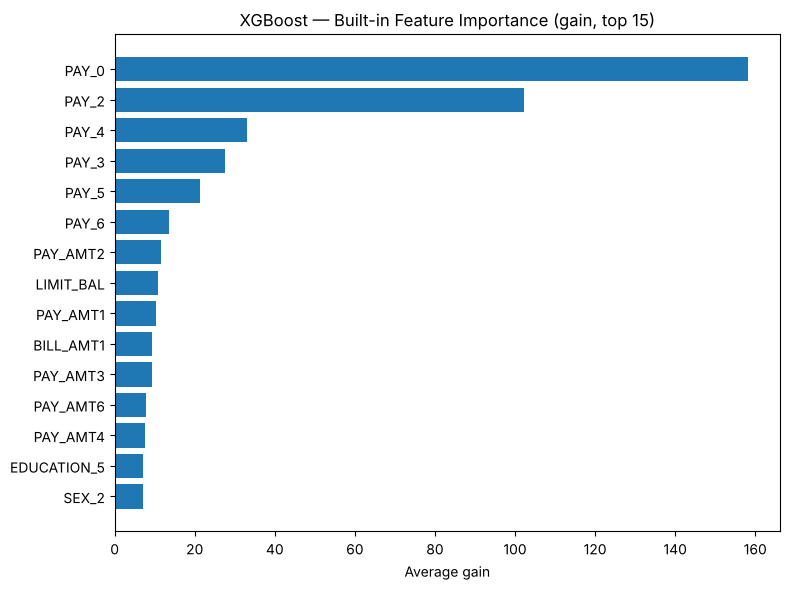

In [21]:
top_gain = importance_table["gain"].sort_values(ascending=True).tail(15)

plt.figure(figsize=(8, 6))
plt.barh(top_gain.index, top_gain.values)
plt.xlabel("Average gain")
plt.title("XGBoost — Built-in Feature Importance (gain, top 15)")
plt.tight_layout()
plt.show()

## 7. Preparation for the explainers (SHAP, LIME, DiCE)

Two things the explainability part needs:

1. **A prediction function on raw (unscaled) inputs.** Explanations must be readable: "`LIMIT_BAL` = 50,000" means something, while "`LIMIT_BAL` = −0.83 standard deviations" doesn't. So we wrap preprocessing and the model into one function, the same way `nn_predict_proba_raw` does in the NN notebook.
2. **One high-risk applicant from the test set**, chosen once and reused across SHAP, LIME and counterfactuals so the three methods can be compared on the same case.

In [22]:
# ==============================================================================
# PREDICTION FUNCTION ON RAW INPUTS (same structure as nn_predict_proba_raw)
# ==============================================================================
def xgb_predict_proba_raw(X_input):
    # SHAP/LIME may pass a NumPy array instead of a DataFrame
    if not isinstance(X_input, pd.DataFrame):
        X_input = pd.DataFrame(
            X_input,
            columns=X_train.columns
        )

    X_processed = preprocessor.transform(X_input)

    return xgb_model.predict_proba(X_processed)

# Two probabilities per client: P(no default), P(default)
xgb_predict_proba_raw(X_test.head())

array([[0.84762114, 0.15237886],
       [0.8717195 , 0.1282805 ],
       [0.8440633 , 0.15593669],
       [0.86305594, 0.13694406],
       [0.96682584, 0.03317413]], dtype=float32)

In [23]:
# Sanity check: the wrapper must give exactly the same probabilities as the model on processed data
assert np.allclose(xgb_predict_proba_raw(X_test)[:, 1], y_proba_xgb)
print("Wrapper OK")

Wrapper OK


### Selecting the high-risk applicant

**Hypothetical decision rule (from the README):** an applicant whose predicted default probability is ≥ 0.50 is treated as **declined**.

**Choice of applicant:** among test clients who were declined **and actually defaulted** (true positives), we take the one whose probability is closest to **0.70**:
- clearly high-risk, so the decision is unambiguous;
- not an extreme case (e.g. 0.95), where no reasonable counterfactual could flip the decision;
- a correct prediction, so we're explaining the model's normal behavior rather than an error.

The rule is deterministic, so every teammate gets the same applicant.

In [24]:
DECISION_THRESHOLD = 0.50
TARGET_PROBA = 0.70

test_results = pd.DataFrame({
    "proba_default": y_proba_xgb,
    "actual_default": y_test.values,
}, index=X_test.index)

# True positives: declined by the rule AND actually defaulted
candidates = test_results[
    (test_results["proba_default"] >= DECISION_THRESHOLD)
    & (test_results["actual_default"] == 1)
]
print("Declined applicants in test set:", (test_results["proba_default"] >= DECISION_THRESHOLD).sum())
print("...of which actually defaulted: ", len(candidates))

# Applicant whose probability is closest to 0.70
selected_idx = (candidates["proba_default"] - TARGET_PROBA).abs().idxmin()

applicant_raw = X_test.loc[[selected_idx]]   # 1-row DataFrame, raw (readable) values
applicant_proba = xgb_predict_proba_raw(applicant_raw)[0, 1]

print(f"\nSelected applicant: df index = {selected_idx}, client ID = {df.loc[selected_idx, 'ID']}")
print(f"Predicted probability of default: {applicant_proba:.3f}  -> DECLINED")
print(f"Actual outcome: {'Default' if y_test.loc[selected_idx] == 1 else 'No default'}")

Declined applicants in test set: 727
...of which actually defaulted:  480

Selected applicant: df index = 24154, client ID = 24155
Predicted probability of default: 0.700  -> DECLINED
Actual outcome: Default


In [25]:
# The applicant's raw profile (transposed for readability)
# PAY_x: repayment status (-2/-1/0 = paid on time or no use; 1 = 1 month late; 2 = 2 months late; ...)
# BILL_AMTx: bill statement amount, PAY_AMTx: amount paid (x = 1 is the most recent month)
applicant_raw.T.rename(columns={selected_idx: "Value"})

,Value
LIMIT_BAL,110000
SEX,1
EDUCATION,2
MARRIAGE,2
AGE,29
PAY_0,2
PAY_2,2
PAY_3,2
PAY_4,2
PAY_5,0


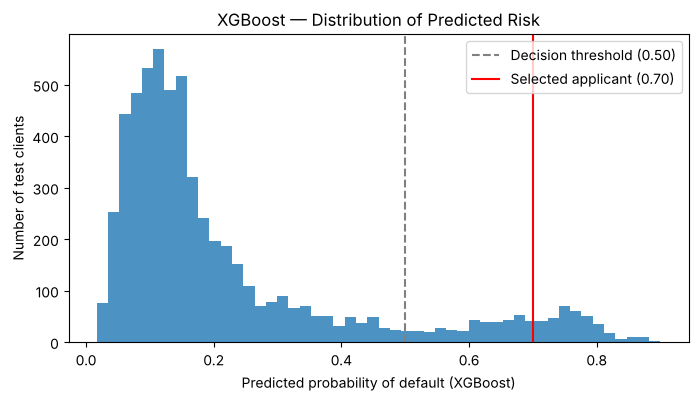

In [26]:
# Where does this applicant sit in the distribution of predicted risk?
plt.figure(figsize=(8, 4))
plt.hist(y_proba_xgb, bins=50, alpha=0.8)
plt.axvline(DECISION_THRESHOLD, linestyle="--", color="grey", label="Decision threshold (0.50)")
plt.axvline(applicant_proba, color="red", label=f"Selected applicant ({applicant_proba:.2f})")
plt.xlabel("Predicted probability of default (XGBoost)")
plt.ylabel("Number of test clients")
plt.title("XGBoost — Distribution of Predicted Risk")
plt.legend()
plt.show()

### Heads-up for the SHAP stress test: correlated features

The README's SHAP stress test is about correlated predictors. The correlations below show how much the six monthly bill amounts overlap: they're very strongly correlated, so the model can rely on any one of them, and SHAP may split the credit among them somewhat arbitrarily.

In [27]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

print("Correlation between monthly bill amounts (train set):")
display(X_train[bill_cols].corr().round(2))

print("Correlation between monthly repayment statuses (train set):")
display(X_train[pay_cols].corr().round(2))

Correlation between monthly bill amounts (train set):


,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
BILL_AMT1,1.00,0.95,0.90,0.86,0.83,0.80
BILL_AMT2,0.95,1.00,0.94,0.89,0.86,0.83
BILL_AMT3,0.90,0.94,1.00,0.93,0.89,0.86
BILL_AMT4,0.86,0.89,0.93,1.00,0.94,0.90
BILL_AMT5,0.83,0.86,0.89,0.94,1.00,0.95
BILL_AMT6,0.80,0.83,0.86,0.90,0.95,1.00


Correlation between monthly repayment statuses (train set):


,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
PAY_0,1.00,0.67,0.57,0.54,0.51,0.48
PAY_2,0.67,1.00,0.76,0.66,0.62,0.58
PAY_3,0.57,0.76,1.00,0.78,0.69,0.63
PAY_4,0.54,0.66,0.78,1.00,0.82,0.71
PAY_5,0.51,0.62,0.69,0.82,1.00,0.81
PAY_6,0.48,0.58,0.63,0.71,0.81,1.00


## Summary

- XGBoost was trained with **exactly the same X/y, split, preprocessing and metrics** as the other models.
- The test-set metrics are in `xgb_metrics`, next to the neural network in `comparison`.
- XGBoost's built-in importance is global, has no direction, and changes with its definition. That gap motivates SHAP, LIME and counterfactuals.
- Objects ready for the explainability part:
  - `xgb_model`: the trained model
  - `preprocessor`: the fitted preprocessing pipeline
  - `xgb_predict_proba_raw`: prediction function on **raw** inputs (use it with LIME and DiCE)
  - `selected_idx`, `applicant_raw`, `applicant_proba`: the high-risk applicant shared by all three methods
  - `X_train`, `X_test`, `y_train`, `y_test`: the shared split

**Implementation boundary:** this notebook prepares prediction wrappers and an applicant, but does not execute SHAP, LIME or DiCE. Its correlation matrices do not constitute a SHAP correlated-feature stress test. The separate PyCaret notebook explains a different model and applicant.
